# Two causal forecasts and Huber on the same observations

**Question:** How do Ridge and histogram boosting trade detection against false alarms when a recovery
shift preserves the instantaneous balance that Huber enforces?

Level 3 · Prerequisites: lessons 01–02 and a basic train/calibration/test split. · Reading time: 55 minutes.

## Objectives

Closing a balance and predicting a familiar operating pattern are different tasks. We will actually fit
OreBridge's histogram gradient boosting and multichannel Ridge predictors, inspect their shared causal lags
and separate normal-error calibrations, then run both beside Huber on identical observations. A controlled
recovery-relation change preserves conservation while breaking the usual channel relationships. An added
feed-bias example and a healthy control expose the tradeoff between missed disturbances and false alarms.
The comparison is deliberately bounded to three held-out cases; it is not a search for the best detector.

## Setup

Work in a checkout of OreBridge with the notebook environment active. The computational methods live in
`data-pipeline/pipeline`, so the checkout is required; no released OreBridge PyPI distribution is implied.
Install the exact numerical dependencies once, outside this notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Start the kernel with `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` and `MKL_NUM_THREADS=1`.
The setup finds the checkout from the working directory without printing a machine path.

In [1]:
# Use the pinned CPU environment and import the implemented scientific methods.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.learning import fit_normal, fit_ridge, lagged, forecast_scores
from pipeline.model.scenarios import generate, channel_specs, conservation_matrix
from pipeline.stages.plant_evaluate import batch_projection, confusion
specs = channel_specs()
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Data

OreBridge owns the MIT-licensed authored synthetic generator in
`data-pipeline/pipeline/model/scenarios.py`; [repository](https://github.com/fsantibanezleal/CAOS_OreBridge).
Its sixteen-channel contract is also committed in `data/derived/PL-01/trace.json`. We regenerate the actual
training seeds 100–107, forecast calibration seeds 200–203, and separate state-calibration seeds 300–307.
Test seed 1000 is excluded from every fit and threshold calculation. `data/derived/state-model.json`
documents the canonical HGB configuration. This notebook fits both learned families, loading neither checkpoint.
The Ridge comparison is local to this lesson; the committed 6144-cell matrix remains the original eight-method experiment.
These original test sequences are already public: adding Ridge is a post-publication extension, not a
prospectively untouched model-selection exercise. Splits still exclude test records from fitting and calibration.

## Method

The maintained [scikit-learn implementation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html) adds regression trees sequentially to reduce a prediction
loss, with features grouped into histogram bins. OreBridge fits one regressor per channel through a
multi-output wrapper. The actual configuration uses 70 boosting iterations, at most 12 leaves per tree,
64 bins, L2 regularization of 1 and random seed 41. These values come from `learning.fit_normal`, not from a
claim that the configuration has been optimized for an operating mine. The training target is the next
observation; the predictor never receives the injected fault mask.

Its feature vector is $(y_{t-1},y_{t-2},y_{t-3},y_{t-4})$ across all sixteen channels. Each target is
later than every feature. Training records are scaled by their channel standard deviations, and the same
scales are reused at prediction time. Division by standard deviation does not itself subtract the mean.
Calibration measures absolute errors on disjoint normal sequences;
per-channel thresholds are their higher empirical 99.5th percentiles. The alarm score is
$s_{tj}=|y_{tj}-\hat y_{tj}|/q_j$, so a score above one means a calibrated exceedance, not a posterior
probability of a fault. Execute the fit and inspect its sample counts first.

In [2]:
# Fit the published numerical estimator on normal sequences without test information.
bundle = fit_normal()
print(f"Normal training rows: {bundle['normal_training_rows']}; "
      f"forecast calibration rows: {bundle['calibration_rows']}")
print("Training / forecast calibration seeds:", bundle["train_seeds"],
      "/", bundle["calibration_seeds"])
print(f"Flotation-feed absolute error threshold: {bundle['threshold'][5]:.6f} t/h")
parameters = bundle["model"].estimators_[0].get_params()
print("Fitted estimator configuration:", {k: parameters[k] for k in ["max_iter", "max_leaf_nodes", "max_bins"]})

Normal training rows: 1568; forecast calibration rows: 784
Training / forecast calibration seeds: [100, 101, 102, 103, 104, 105, 106, 107] / [200, 201, 202, 203]
Flotation-feed absolute error threshold: 23.772435 t/h
Fitted estimator configuration: {'max_iter': 70, 'max_leaf_nodes': 12, 'max_bins': 64}


Inspect one design matrix through the imported lag constructor. With 200 observations and four preceding
steps, there are 196 targets and 64 features. The first target is at second four; its four input blocks
refer to seconds three, two, one and zero. This ordering matters when diagnosing leakage: a random split
of overlapping time windows can leak near-duplicates even if a model's API looks innocuous. Here complete
seeded sequences, rather than individual windows, separate fitting and calibration.

In [3]:
# Expose the causal window ordering before scoring a held-out disturbance.
normal_sequence = generate(seed=100, steps=200)
features, targets = lagged(normal_sequence.observed)
print(f"Feature matrix: {features.shape}; target matrix: {targets.shape}")
print("First feed history, newest to oldest, t/h:", np.round(features[0, [0, 16, 32, 48]], 4))
print(f"Following feed observation: {targets[0, 0]:.4f} t/h")

Feature matrix: (196, 64); target matrix: (196, 16)
First feed history, newest to oldest, t/h: [766.6319 748.7098 755.8005 765.56  ]
Following feed observation: 765.9217 t/h


Now fit a genuinely different predictor on that same lag design. [Ridge regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) uses a
linear coefficient matrix and an intercept, minimizing
$\|\widetilde Y-\widetilde X B-\mathbf{1}b^T\|_F^2+\alpha\|B\|_F^2$.
Here $B$ has 64 feature rows and 16 target columns; scikit-learn stores its transpose in `coef_`.
For this retrospective extension we freeze $\alpha=1$, an intercept and the SVD solver before measuring Ridge's
test results. The shrinkage penalty discourages large coefficients when lagged
channels are correlated. It does not impose conservation or turn regression coefficients into causal edges.

The imported `fit_ridge` trains on the same eight normal seeds and calibrates errors on the same four
separate seeds as HGB. It reuses the training standard-deviation scaling convention and supplies its own
higher 99.5th-percentile error threshold for each target. Thus we compare a regularized linear mapping
with histogram trees while keeping history, target units and data partitions fixed. The maintained estimator
solves the regression; no fitting algorithm is implemented inside this notebook.

In [4]:
# Fit the regularized linear family with the same normal seeds and its own forecast-error calibration.
ridge_bundle = fit_ridge(train_seeds=range(100, 108), calibration_seeds=range(200, 204), alpha=1.0)
print(f"Ridge: training rows={ridge_bundle['normal_training_rows']}; "
      f"calibration rows={ridge_bundle['calibration_rows']}")
print("Coefficient matrix, targets × features:", ridge_bundle["model"].coef_.shape)
print("Causal lag features:", ridge_bundle["model"].n_features_in_)
ridge_parameters = ridge_bundle["model"].get_params()
print("Fixed Ridge configuration:", {k: ridge_parameters[k] for k in ["alpha", "fit_intercept", "solver"]})
print(f"Ridge flotation-feed error threshold: {ridge_bundle['threshold'][5]:.6f} t/h")

Ridge: training rows=1568; calibration rows=784
Coefficient matrix, targets × features: (16, 64)
Causal lag features: 64
Fixed Ridge configuration: {'alpha': 1.0, 'fit_intercept': True, 'solver': 'svd'}
Ridge flotation-feed error threshold: 21.892671 t/h


Inspect the fitted linear map for concentrate solids before opening a test case. Reshaping its 64
coefficients into four lag rows and sixteen channel columns follows the actual `lagged` ordering. These
weights act on scaled inputs, so the color scale is dimensionless. Their values show what the fitted
normal-state predictor uses; their interpretation depends on the other correlated channels remaining in the model.

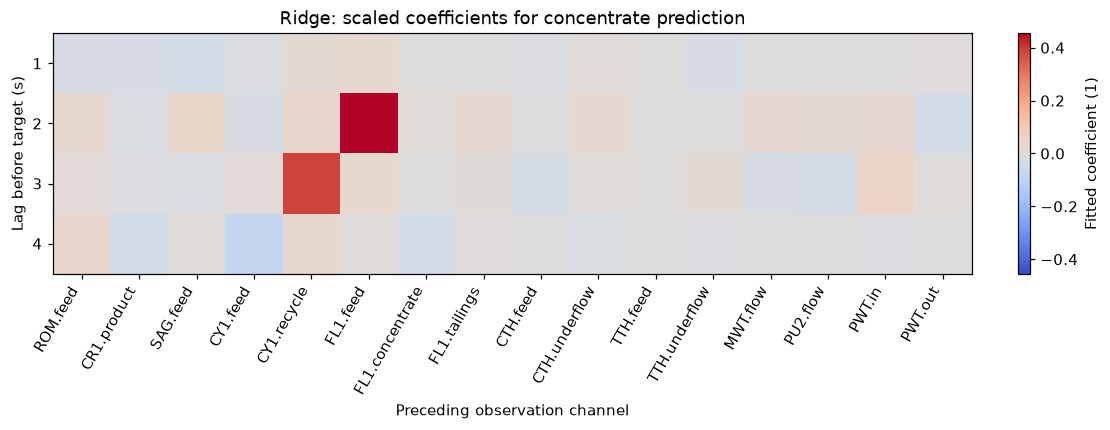

Declared feed-to-concentrate delay difference: 2 s
Declared recycle-to-concentrate delay difference: 3 s


In [5]:
# Read the learned linear coefficients in the actual multichannel causal-lag layout.
concentrate_weights = ridge_bundle["model"].coef_[6].reshape(4, 16)
color_limit = max(float(np.max(np.abs(concentrate_weights))), 1e-12)
fig, axis = plt.subplots(figsize=(10, 3.8), layout="constrained")
colors = axis.imshow(concentrate_weights, aspect="auto", cmap="coolwarm",
                     vmin=-color_limit, vmax=color_limit)
axis.set_xticks(np.arange(16), [s["id"] for s in specs], rotation=60, ha="right")
axis.set_yticks(np.arange(4), [1, 2, 3, 4])
axis.set(title="Ridge: scaled coefficients for concentrate prediction", xlabel="Preceding observation channel",
         ylabel="Lag before target (s)")
fig.colorbar(colors, ax=axis, label="Fitted coefficient (1)")
plt.show()
print("Declared feed-to-concentrate delay difference:", specs[6]["delay_s"] - specs[5]["delay_s"], "s")
print("Declared recycle-to-concentrate delay difference:", specs[6]["delay_s"] - specs[4]["delay_s"], "s")

A colored cell is a conditional linear prediction weight, not a physical transfer fraction. Repeated
lags and channels carry overlapping information about the synthetic load, so several coefficient patterns
can produce similar forecasts. Ridge selects one penalized solution; large weights or negative signs do
not establish causation. Feed at lag two and recycle at lag three have large positive weights in this fit;
they coincide with the generator's declared two- and three-second transport differences. This agreement
illustrates a known synthetic construction, not an independently measured residence time. The linear map can extrapolate along a changed
input direction. Whether that helps detection or spreads alerts to unaffected channels must be measured
on the test cases below rather than inferred from the coefficient image alone.

Huber reconciliation asks for an estimate compatible with $Ax=0$ while limiting large-residual influence
([Huber loss](https://doi.org/10.1214/aoms/1177703732)). It has no memory of normal recovery relationships beyond those equations.
To make the input comparison exact, we apply Huber to the very same clock-time vectors used by the
predictors. We calibrate this input convention with normal seeds 300–307; this is an explicitly labeled
same-clock Huber experiment, distinct from the canonical parcel-aligned robust benchmark in lesson 04.
The uncertainty vector is the generator's declared sensor scale. The package performs every robust
projection; the cell only pools its normal scores and selects their empirical quantiles.

Calibration accommodates the ordinary residuals of normal transport transitions. It cannot repair a
mistaken balance model or make a balanced disturbance identifiable. All three methods begin scoring at second
fourteen so they see exactly the same 146 × 16 test entries; no threshold is tuned on those entries.

In [6]:
# Calibrate the same-clock Huber residual without using the held-out cases.
matrix = conservation_matrix()
sigma = np.array([s["sigma"] for s in specs])
normal_scores = []
for seed in range(300, 308):
    normal_case = generate(seed=seed)
    scores, _, _ = batch_projection(normal_case.observed[14:], sigma, matrix, robust=True)
    normal_scores.append(scores)
robust_threshold = np.quantile(np.concatenate(normal_scores), 0.995, axis=0, method="higher")
robust_threshold = np.maximum(robust_threshold, 0.1)
print(f"Separate state-calibration rows: {sum(len(x) for x in normal_scores)}")
print(f"Flotation-feed robust score threshold: {robust_threshold[5]:.6f} σ")

Separate state-calibration rows: 1168
Flotation-feed robust score threshold: 6.736266 σ


## Comparison

The generator's `engine` family changes the concentrate/tailings split while preserving each affected
conservation equation. It represents a changed process relation or incompatible fixed engine model, not
a proven defective sensor. We first forecast the held-out observations, keeping prediction, residual score
and known fault label in separate variables. A valid causal model can still miss the onset of an abrupt
change; scoring every affected point, rather than expanding one alarm over an interval, makes that visible.

In [7]:
# Run the fitted causal predictor on new observations and retain every pointwise error.
changed_relation = generate("engine", seed=1000, severity=2)
forecast_score = forecast_scores(bundle, changed_relation.observed)[14:]
test_features, _ = lagged(changed_relation.observed)
forecast = bundle["model"].predict(test_features / np.tile(bundle["scale"], 4)) * bundle["scale"]
forecast = forecast[14 - bundle["lags"]:]
truth = changed_relation.fault[14:]
forecast_metrics = confusion(forecast_score > 1, truth)
print(f"HGB: TP={forecast_metrics['tp']}, FP={forecast_metrics['fp']}, FN={forecast_metrics['fn']}")
print(f"Recall: {forecast_metrics['recall']:.6f}; "
      f"false-positive rate: {forecast_metrics['false_positive_rate']:.6f}")

HGB: TP=291, FP=19, FN=9
Recall: 0.970000; false-positive rate: 0.009332


Apply the independently fitted Ridge bundle to the identical causal test windows. Its score is divided
by its own normal-error threshold, just as HGB uses its own threshold. We keep the forecast in t/h as well
as the score, because a normalized exceedance can hide the magnitude and direction of an extrapolation.
No fit, coefficient, scale or threshold changes in response to this recovery-shift case.

In [8]:
# Use the same raw observations and causal windows for the second fitted family.
ridge_score = forecast_scores(ridge_bundle, changed_relation.observed)[14:]
ridge_inputs = test_features / np.tile(ridge_bundle["scale"], ridge_bundle["lags"])
ridge_forecast = ridge_bundle["model"].predict(ridge_inputs) * ridge_bundle["scale"]
ridge_forecast = ridge_forecast[14 - ridge_bundle["lags"]:]
ridge_metrics = confusion(ridge_score > 1, truth)
print(f"Ridge: TP={ridge_metrics['tp']}, FP={ridge_metrics['fp']}, FN={ridge_metrics['fn']}")
print(f"Recall: {ridge_metrics['recall']:.6f} "
      f"({100 * ridge_metrics['recall']:.6f}%); "
      f"false-positive rate: {ridge_metrics['false_positive_rate']:.6f}")

Ridge: TP=296, FP=165, FN=4
Recall: 0.986667 (98.666667%); false-positive rate: 0.081041


Run the implemented batch Huber projection on those exact observations, with the previously fixed normal
thresholds. To isolate the reason conservation is weak here, regenerate the healthy counterpart with the
same seed. Subtracting it cancels the same random measurement noise and reveals the injected change alone.
If its product with the conservation matrix is zero, the changed operating relation lies in the balance's
null space: no amount of exact balance closure can distinguish it from another balanced state.

In [9]:
# Hold input values fixed and measure the conservation-null disturbance explicitly.
robust_score, robust_state, robust_iterations = batch_projection(
    changed_relation.observed[14:], sigma, matrix, robust=True
)
robust_metrics = confusion(robust_score > robust_threshold, truth)
healthy_counterpart = generate("healthy", seed=1000, severity=2)
injected_change = changed_relation.observed - healthy_counterpart.observed
print(f"Huber: TP={robust_metrics['tp']}, FP={robust_metrics['fp']}, FN={robust_metrics['fn']}")
print(f"Recall: {robust_metrics['recall']:.6f}; "
      f"false-positive rate: {robust_metrics['false_positive_rate']:.6f}")
print(f"Largest factor response to the injected shift: {np.max(np.abs(injected_change @ matrix.T)):.12f}")

Huber: TP=0, FP=4, FN=300
Recall: 0.000000; false-positive rate: 0.001965
Largest factor response to the injected shift: 0.000000000000


Focus on concentrate solids to see the changed relationship in engineering units, then compare normalized
alarm scores for that same channel. Each method's score is divided by its own calibrated threshold, so all
share an exceedance level of one. This scale convention makes the alarm rule comparable;
it does not make the underlying loss functions, information sources or score distributions equivalent.

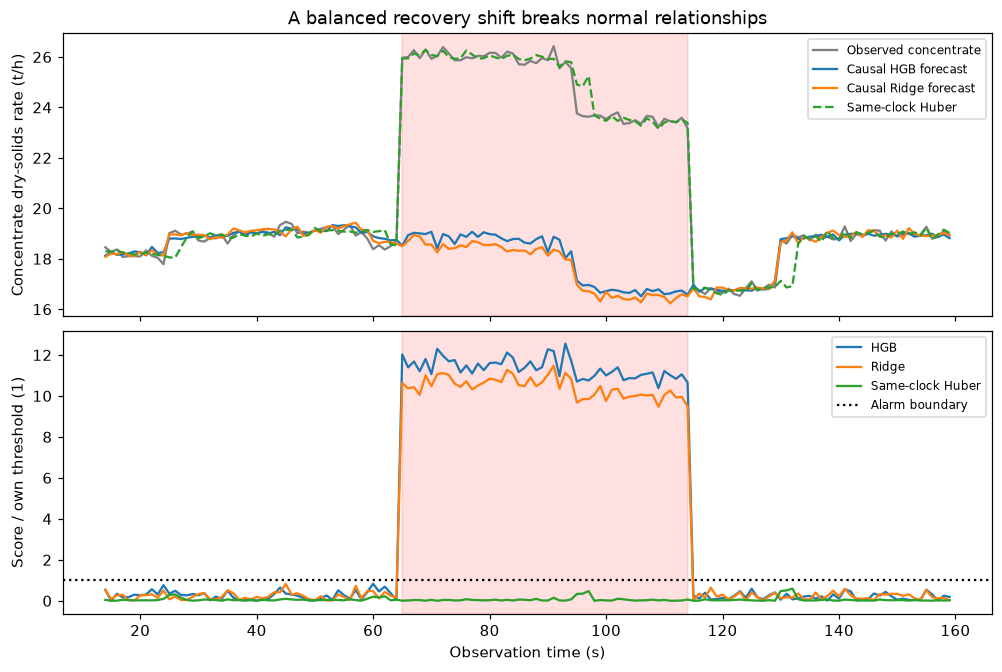

In [10]:
# Show the same concentrate observations, three predictions or estimates and their own calibrated scores.
time_s = np.arange(14, 160)
channel = 6
fig, axes = plt.subplots(2, 1, figsize=(9, 6), layout="constrained", sharex=True)
axes[0].plot(time_s, changed_relation.observed[14:, channel], color="grey", label="Observed concentrate")
axes[0].plot(time_s, forecast[:, channel], color="tab:blue", label="Causal HGB forecast")
axes[0].plot(time_s, ridge_forecast[:, channel], color="tab:orange", label="Causal Ridge forecast")
axes[0].plot(time_s, robust_state[:, channel], color="tab:green", linestyle="--", label="Same-clock Huber")
axes[0].set(title="A balanced recovery shift breaks normal relationships", ylabel="Concentrate dry-solids rate (t/h)")
axes[1].plot(time_s, forecast_score[:, channel], color="tab:blue", label="HGB")
axes[1].plot(time_s, ridge_score[:, channel], color="tab:orange", label="Ridge")
axes[1].plot(time_s, robust_score[:, channel] / robust_threshold[channel], color="tab:green", label="Same-clock Huber")
axes[1].axhline(1, color="black", linestyle=":", label="Alarm boundary")
axes[1].set(xlabel="Observation time (s)", ylabel="Score / own threshold (1)")
for axis in axes:
    axis.axvspan(65, 114, alpha=0.12, color="red")
    axis.legend(fontsize=8)
plt.show()

The forecasts respond to the changed concentrate relationship according to their fitted function families,
while a conservation-compatible Huber state can stay near the changed observation. The score panel separates
temporal surprise from the correction needed to close a balance. Here both concentrate forecasts stay close
to the normal relationship while the measured concentrate shifts upward, keeping their scores well above one.
Agreement on that channel does not guarantee the same alert behavior elsewhere in the network.
The red interval marks truth only for interpretation. A larger forecast score does not establish
whether the process, the instrument, or the fixed relation has changed.

Now add a direct feed bias and a healthy control without changing fitted models or thresholds. Pooling only
the recovery-shift example would hide the alert burden. Precision is undefined when no alarm is raised;
recall is undefined when no fault exists. The imported confusion calculation returns null in those cases.
We preserve that value instead of treating a healthy-control recall as either perfect or zero.

In [11]:
# Keep held-out controls and every false alarm in the comparison.
comparisons = {"engine": {"HGB": forecast_metrics, "Ridge": ridge_metrics, "Huber": robust_metrics}}
for family in ["bias", "healthy"]:
    case = generate(family, seed=1000, severity=2)
    predicted = forecast_scores(bundle, case.observed)[14:]
    ridge_predicted = forecast_scores(ridge_bundle, case.observed)[14:]
    projected, _, _ = batch_projection(case.observed[14:], sigma, matrix, robust=True)
    comparisons[family] = {
        "HGB": confusion(predicted > 1, case.fault[14:]),
        "Ridge": confusion(ridge_predicted > 1, case.fault[14:]),
        "Huber": confusion(projected > robust_threshold, case.fault[14:]),
    }
family_names = {"engine": "Recovery shift", "bias": "Feed bias", "healthy": "Healthy control"}
for family, methods in comparisons.items():
    for method, metrics in methods.items():
        recall_text = "null (undefined)" if metrics["recall"] is None else f"{metrics['recall']:.6f}"
        print(f"{family_names[family]} / {method}: recall={recall_text}; "
              f"TP={metrics['tp']}; FN={metrics['fn']}; false alarms={metrics['fp']}")

Recovery shift / HGB: recall=0.970000; TP=291; FN=9; false alarms=19
Recovery shift / Ridge: recall=0.986667; TP=296; FN=4; false alarms=165
Recovery shift / Huber: recall=0.000000; TP=0; FN=300; false alarms=4
Feed bias / HGB: recall=1.000000; TP=50; FN=0; false alarms=62
Feed bias / Ridge: recall=1.000000; TP=50; FN=0; false alarms=67
Feed bias / Huber: recall=0.700000; TP=35; FN=15; false alarms=4
Healthy control / HGB: recall=null (undefined); TP=0; FN=0; false alarms=9
Healthy control / Ridge: recall=null (undefined); TP=0; FN=0; false alarms=10
Healthy control / Huber: recall=null (undefined); TP=0; FN=0; false alarms=4


Compare recall only where a disturbance denominator exists and show false-positive rates for all three
cases. The two panels use percentages but have different denominators: affected channel-time entries for
recall, unaffected entries for false positives. Counting either quantity at event level would answer a
different question. The small number of cases supports a mechanistic lesson, not a confidence interval
for an industrial fleet or a claim of broad superiority.

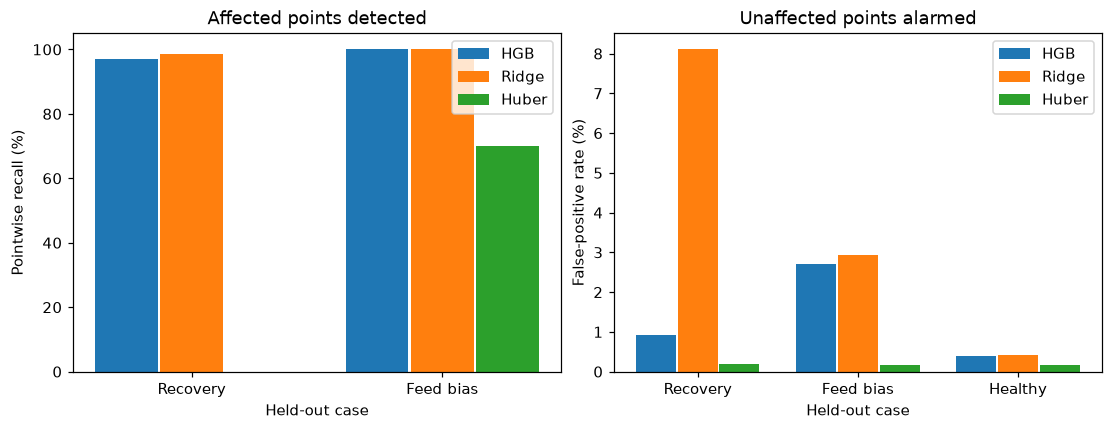

In [12]:
# Make detection gains and false-alert costs visible with their distinct denominators.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for offset, method in [(-0.26, "HGB"), (0.0, "Ridge"), (0.26, "Huber")]:
    recalls = [100 * comparisons[f][method]["recall"] for f in ["engine", "bias"]]
    false_rates = [100 * comparisons[f][method]["false_positive_rate"] for f in comparisons]
    axes[0].bar(np.arange(2) + offset, recalls, 0.25, label=method)
    axes[1].bar(np.arange(3) + offset, false_rates, 0.25, label=method)
axes[0].set_xticks([0, 1], ["Recovery", "Feed bias"])
axes[1].set_xticks([0, 1, 2], ["Recovery", "Feed bias", "Healthy"])
axes[0].set(title="Affected points detected", ylabel="Pointwise recall (%)", xlabel="Held-out case")
axes[1].set(title="Unaffected points alarmed", ylabel="False-positive rate (%)", xlabel="Held-out case")
for axis in axes:
    axis.legend()
plt.show()

Ridge detects 296 affected points in the recovery case, compared with HGB's 291, but produces 165 false
alerts compared with 19. Its gain of five detections comes with 146 additional alerts on unaffected entries.
The healthy control has ten Ridge alerts and nine HGB alerts; one control sequence cannot certify either
calibration. To locate the larger recovery-case cost, break false alerts down by channel. Normalize each
count by that channel's unaffected entries, since affected and unaffected channels have different eligible denominators.

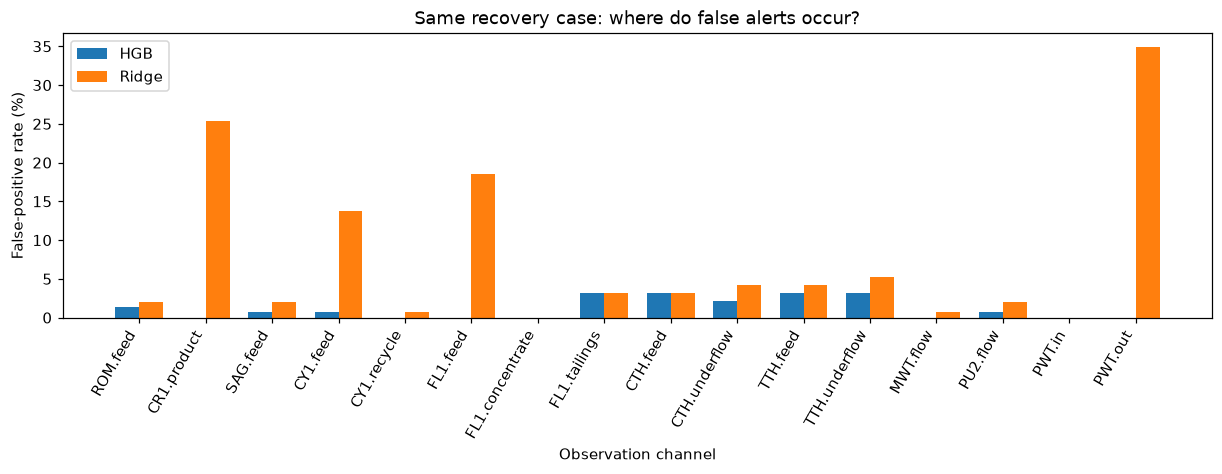

Additional Ridge detections: 5; additional false alerts: 146
PWT.out: Ridge=51, HGB=0, unaffected entries=146
CR1.product: Ridge=37, HGB=0, unaffected entries=146
FL1.feed: Ridge=27, HGB=0, unaffected entries=146
CY1.feed: Ridge=20, HGB=1, unaffected entries=146


In [13]:
# Locate the false-alert burden on identical unaffected channel-time entries.
eligible = (~truth).sum(axis=0)
hgb_false = ((forecast_score > 1) & ~truth).sum(axis=0)
ridge_false = ((ridge_score > 1) & ~truth).sum(axis=0)
positions = np.arange(16)
fig, axis = plt.subplots(figsize=(11, 4.2), layout="constrained")
axis.bar(positions - 0.18, 100 * hgb_false / eligible, 0.36, label="HGB")
axis.bar(positions + 0.18, 100 * ridge_false / eligible, 0.36, label="Ridge")
axis.set_xticks(positions, [s["id"] for s in specs], rotation=60, ha="right")
axis.set(title="Same recovery case: where do false alerts occur?",
         xlabel="Observation channel", ylabel="False-positive rate (%)")
axis.legend()
plt.show()
extra_detections = ridge_metrics["tp"] - forecast_metrics["tp"]
extra_alerts = ridge_metrics["fp"] - forecast_metrics["fp"]
print(f"Additional Ridge detections: {extra_detections}; additional false alerts: {extra_alerts}")
for j in np.argsort(ridge_false)[-4:][::-1]:
    print(f"{specs[j]['id']}: Ridge={ridge_false[j]}, HGB={hgb_false[j]}, unaffected entries={eligible[j]}")

Ridge raises 51 false alerts on water-tank outflow (`PWT.out`) and 37 on crusher product (`CR1.product`),
while HGB raises none on either channel. Both are outside the injected recovery change. These extra alarms
remain errors against known synthetic truth. Both learned families receive identical observations, causal windows and valid entries,
so timing alignment or a different rejection policy cannot explain this local discrepancy. The linear
coefficient map makes cross-channel propagation of a changed relationship plausible, but it cannot attribute
each false alert to a particular weight. A high recall accompanied by this alert burden is a tradeoff that
must remain visible, rather than a general advantage claim for the linear family.

Published graph-based anomaly forecasting already learns sensor relationships: [GDN](https://arxiv.org/abs/2106.06947)
is relevant prior work. We have not implemented or run GDN here, and the histogram predictor is not renamed
as a graph network. The executed published components are scikit-learn's histogram boosting and Ridge,
plus the Huber loss implemented by OreBridge's robust projection. This distinction prevents a citation from becoming an
unearned experimental comparison.

## Results

**Answer:** Both fitted predictors use 1568 normal training rows and 784 forecast-calibration rows. On the
balanced recovery shift, Ridge detects 296 of 300 affected points (98.666667%), HGB detects 291 (97.000000%),
and same-clock Huber detects 0. Their false-alert counts are 165, 19 and 4, respectively. For the feed bias,
Ridge and HGB both detect 50 of 50 points, while Huber detects 35 (70.000000%); their false alerts are 67,
62 and 4. Healthy-control false alerts are 10, 9 and 4, with undefined recall. Ridge's local recall gain
therefore carries a substantial alert cost, rather than establishing general superiority.

A predictor's surprise can reveal a balance-preserving change because its training supplies additional
statistical structure. It can also flag unfamiliar healthy behavior. This experiment uses finite, valid
observations throughout; missing values, source timestamp rejection and model compatibility require the
explicit treatment in the final lesson.

## Summary

The three algorithms encode different knowledge. The learned linear and tree mappings predict normal relationships;
Huber reconciliation constrains admitted conservation equations.
We fitted and calibrated them without future inputs or test-derived thresholds, using the same known test values.
This retrospective extension supports a descriptive comparison; a new prospective evaluation is still needed.
A balanced process change can defeat a balance residual even when that residual is computed perfectly.

## References

- scikit-learn, `HistGradientBoostingRegressor`, exact installed version 1.9.1: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html
- scikit-learn, `Ridge`, fitted multi-target linear estimator, version 1.9.1: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
- Huber (1964), *Robust Estimation of a Location Parameter*: https://doi.org/10.1214/aoms/1177703732
- Deng and Hooi (2021), *Graph Neural Network-Based Anomaly Detection in Multivariate Time Series*,
  cited as prior work, not an executed comparator: https://arxiv.org/abs/2106.06947
- Executed code: `data-pipeline/pipeline/model/learning.py` and
  `data-pipeline/pipeline/stages/plant_evaluate.py`; canonical model manifest: `data/derived/state-model.json`.